# Benchmark Evaluation: CLIP vs. TF-IDF + Logistic Regression

This notebook loads the saved pretrained CLIP encoder, saved TF-IDF vectorizer, and saved logistic-regression classifier; runs inference on each benchmark image/alternative-text pair; and exports predictions and (when valid instance-level labels are available) evaluation metrics.

**Model inputs**
- CLIP: `image_path` + `alt_text`
- TF-IDF + Logistic Regression: `alt_text` only

**Ground-truth caution:** `benchmark_original_label` may be document-level (for example, `failed`) and must not automatically be treated as an individual figure label. This notebook uses `alt_text_class` as the candidate binary target, but only computes metrics on records whose granularity and review status are eligible under the settings below. Predictions are generated for all rows regardless of metric eligibility.

## 1. Mount Google Drive and import packages

In [1]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError
from transformers import CLIPModel, CLIPProcessor
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.14.1+cpu
CUDA available: False


## 2. Configure file paths and evaluation settings
Update the paths if your Drive folders differ. The model directory below matches the `clip_training_results` folder used in your uploaded notebook.

In [2]:
PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "EEE6778_Semester_Project"
)

BENCHMARK_DIR = os.path.join(
    PROJECT_DIR,
    "benchmark_data_folder"
)

BENCHMARK_CSV = os.path.join(
    BENCHMARK_DIR,
    "pdf_benchmark_dataset.csv"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "clip_training_results"
)

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "benchmark_final_evaluation"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Candidate per-alt-text ground-truth column.
# Do not substitute benchmark_original_label unless its granularity
# and meaning have been verified as an instance-level target.
GROUND_TRUTH_COL = "alt_text_class"

# Exclude rows explicitly flagged for manual review from metric calculation.
# Predictions will still be generated for these rows.
EXCLUDE_MANUAL_REVIEW = True

# Eligible granularity values for per-image/per-figure metrics.
# Add values only after confirming they represent instance-level labels.
INSTANCE_GRANULARITY_VALUES = {
    "figure", "figure_level", "image", "instance",
    "figure-level", "image-level"
}

# Keep False unless you have independently verified that alt_text_class
# is a binary label for each individual image/figure, including rows whose
# label_granularity is "document".
ALLOW_DOCUMENT_LEVEL_GRANULARITY = False

# Label mapping for alt_text_class. Numeric 0/1 values are also supported.
# Update only if your dataset uses different class names.
LABEL_MAP = {
    "0": 0,
    "1": 1,
    "nonmeaningful": 0,
    "meaningful": 1
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Benchmark CSV:", BENCHMARK_CSV)
print("Model directory:", MODEL_DIR)
print("Output directory:", OUTPUT_DIR)

Device: cpu
Benchmark CSV: /content/drive/MyDrive/EEE6778_Semester_Project/benchmark_data_folder/pdf_benchmark_dataset.csv
Model directory: /content/drive/MyDrive/EEE6778_Semester_Project/clip_training_results
Output directory: /content/drive/MyDrive/EEE6778_Semester_Project/benchmark_final_evaluation


## 3. Load and inspect the benchmark CSV
This cell checks the required columns and prints label/granularity distributions before any metric calculation.

In [6]:
# ============================================================
# 3. LOAD AND INSPECT THE BENCHMARK CSV
# ============================================================

# Benchmark directory.
BENCHMARK_DIR = (
    "/content/drive/MyDrive/EEE6778_Semester_Project/"
    "benchmark_data_folder"
)

# Benchmark CSV path.
BENCHMARK_CSV = os.path.join(
    BENCHMARK_DIR,
    "pdf_benchmark_dataset.csv"
)

# Load benchmark dataset.
benchmark_df = pd.read_csv(BENCHMARK_CSV)

print("Benchmark dataset loaded successfully.")
print("Benchmark CSV:", BENCHMARK_CSV)


# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = [
    "document_id",
    "page_id",
    "figure_id",
    "image_path",
    "alt_text",
    "alt_text_class",
    "alt_text_type",
    "dataset_source",
    "label_source",
    "benchmark_original_label",
    "label_granularity",
    "manual_review_required"
]

missing_columns = [
    col for col in required_columns
    if col not in benchmark_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required benchmark columns: {missing_columns}"
    )

print("\nAll required benchmark columns are present.")


# ============================================================
# RESOLVE IMAGE PATHS
# ============================================================

def resolve_image_path(image_path):

    if pd.isna(image_path):
        return None

    image_path = str(image_path).strip()

    if not image_path:
        return None

    # Preserve existing absolute paths.
    if os.path.isabs(image_path):
        return image_path

    # Resolve relative paths against benchmark directory.
    return os.path.join(
        BENCHMARK_DIR,
        image_path
    )


benchmark_df["resolved_image_path"] = (
    benchmark_df["image_path"].apply(resolve_image_path)
)

# Check whether images exist.
benchmark_df["image_exists"] = (
    benchmark_df["resolved_image_path"]
    .apply(
        lambda path: (
            os.path.isfile(path)
            if path is not None
            else False
        )
    )
)


# ============================================================
# DATASET OVERVIEW
# ============================================================

print("\n" + "=" * 60)
print("BENCHMARK DATASET OVERVIEW")
print("=" * 60)

print("Total benchmark records:", len(benchmark_df))

print(
    "Unique documents:",
    benchmark_df["document_id"].nunique()
)

print(
    "Unique figures:",
    benchmark_df["figure_id"].nunique()
)

print(
    "Existing images:",
    benchmark_df["image_exists"].sum()
)

print(
    "Missing images:",
    (~benchmark_df["image_exists"]).sum()
)

print(
    "Missing alt text:",
    benchmark_df["alt_text"].isna().sum()
)


# ============================================================
# INSPECT LABEL DISTRIBUTIONS
# ============================================================

print("\n" + "=" * 60)
print("ALT-TEXT CLASS DISTRIBUTION")
print("=" * 60)

print(
    benchmark_df["alt_text_class"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nALT-TEXT TYPE DISTRIBUTION")

print(
    benchmark_df["alt_text_type"]
    .value_counts(dropna=False)
)

print("\nORIGINAL BENCHMARK LABEL DISTRIBUTION")

print(
    benchmark_df["benchmark_original_label"]
    .value_counts(dropna=False)
)

print("\nLABEL SOURCE DISTRIBUTION")

print(
    benchmark_df["label_source"]
    .value_counts(dropna=False)
)

print("\nLABEL GRANULARITY DISTRIBUTION")

print(
    benchmark_df["label_granularity"]
    .value_counts(dropna=False)
)

print("\nMANUAL REVIEW DISTRIBUTION")

print(
    benchmark_df["manual_review_required"]
    .value_counts(dropna=False)
)


# ============================================================
# DISPLAY SAMPLE RECORDS
# ============================================================

print("\n" + "=" * 60)
print("SAMPLE BENCHMARK RECORDS")
print("=" * 60)

display(
    benchmark_df[
        [
            "document_id",
            "figure_id",
            "alt_text",
            "alt_text_class",
            "alt_text_type",
            "label_source",
            "label_granularity",
            "manual_review_required",
            "image_exists"
        ]
    ].head(10)
)

Benchmark dataset loaded successfully.
Benchmark CSV: /content/drive/MyDrive/EEE6778_Semester_Project/benchmark_data_folder/pdf_benchmark_dataset.csv

All required benchmark columns are present.

BENCHMARK DATASET OVERVIEW
Total benchmark records: 21
Unique documents: 6
Unique figures: 7
Existing images: 21
Missing images: 0
Missing alt text: 7

ALT-TEXT CLASS DISTRIBUTION
alt_text_class
0    14
1     7
Name: count, dtype: int64

ALT-TEXT TYPE DISTRIBUTION
alt_text_type
nonmeaningful    14
meaningful        7
Name: count, dtype: int64

ORIGINAL BENCHMARK LABEL DISTRIBUTION
benchmark_original_label
failed         7
passed         7
not_present    7
Name: count, dtype: int64

LABEL SOURCE DISTRIBUTION
label_source
document_level_benchmark    21
Name: count, dtype: int64

LABEL GRANULARITY DISTRIBUTION
label_granularity
document    21
Name: count, dtype: int64

MANUAL REVIEW DISTRIBUTION
manual_review_required
True    21
Name: count, dtype: int64

SAMPLE BENCHMARK RECORDS


,document_id,figure_id,alt_text,alt_text_class,alt_text_type,label_source,label_granularity,manual_review_required,image_exists
0,W3005755974_0,W3005755974_0#0,Figure 6,0,nonmeaningful,document_level_benchmark,document,True,True
1,W4383621582_0,W4383621582_0#0,image,0,nonmeaningful,document_level_benchmark,document,True,True
2,W2929611936_1,W2929611936_1#1,Embedded Image,0,nonmeaningful,document_level_benchmark,document,True,True
3,W2929611936_1,W2929611936_1#0,image,0,nonmeaningful,document_level_benchmark,document,True,True
4,W2929611936_0,W2929611936_0#0,image,0,nonmeaningful,document_level_benchmark,document,True,True
5,W2460269320_0,W2460269320_0#0,"Stuart, Florida",0,nonmeaningful,document_level_benchmark,document,True,True
6,W4206740007_0,W4206740007_0#0,Three Panels,0,nonmeaningful,document_level_benchmark,document,True,True
7,W3005755974_0,W3005755974_0#0,A detailed specification curve analysis showin...,1,meaningful,document_level_benchmark,document,True,True
8,W4383621582_0,W4383621582_0#0,"A flowchart titled ""Diagram of Process for Sel...",1,meaningful,document_level_benchmark,document,True,True
9,W2929611936_1,W2929611936_1#1,Panel A\nA contour plot showing the change in ...,1,meaningful,document_level_benchmark,document,True,True


## 4. Load saved model configuration and artifacts
Expected files in `clip_training_results`:
- `model_config.json`
- `logistic_regression_model.pkl`
- `tfidf_vectorizer.pkl`

The CLIP model itself is reloaded from the pretrained Hugging Face model identifier in the configuration. This is appropriate for the training code supplied, which initialized CLIP with `from_pretrained()` and did not show fine-tuning.

In [7]:
config_path = os.path.join(MODEL_DIR, "model_config.json")
lr_model_path = os.path.join(MODEL_DIR, "logistic_regression_model.pkl")
tfidf_path = os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")

for path in [config_path, lr_model_path, tfidf_path]:
    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Required saved artifact not found: {path}\n"
            "Save the fitted classifier and fitted TF-IDF vectorizer "
            "from the original training notebook. Do not refit them on "
            "the benchmark dataset."
        )

with open(config_path, "r") as f:
    config = json.load(f)

required_config_keys = [
    "clip_model",
    "clip_similarity_threshold",
    "logistic_regression_threshold"
]
missing_config_keys = [
    key for key in required_config_keys if key not in config
]
if missing_config_keys:
    raise KeyError(
        f"Missing keys in model_config.json: {missing_config_keys}"
    )

CLIP_MODEL_NAME = config["clip_model"]
CLIP_THRESHOLD = float(config["clip_similarity_threshold"])
LR_THRESHOLD = float(config["logistic_regression_threshold"])

processor = CLIPProcessor.from_pretrained(CLIP_MODEL_NAME)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL_NAME).to(DEVICE)
clip_model.eval()

logistic_model = joblib.load(lr_model_path)
tfidf_vectorizer = joblib.load(tfidf_path)

if 1 not in list(logistic_model.classes_):
    raise ValueError(
        f"Expected positive class 1, found classes: {logistic_model.classes_}"
    )

print("CLIP model:", CLIP_MODEL_NAME)
print("CLIP threshold:", CLIP_THRESHOLD)
print("Logistic regression threshold:", LR_THRESHOLD)
print("Logistic classes:", logistic_model.classes_)
print("TF-IDF vocabulary size:", len(tfidf_vectorizer.vocabulary_))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP model: openai/clip-vit-base-patch32
CLIP threshold: 0.23571069538593292
Logistic regression threshold: 0.44673682954589106
Logistic classes: [0 1]
TF-IDF vocabulary size: 2449


## 5. Resolve benchmark image paths
The CSV may contain absolute paths or paths relative to the benchmark folder. This cell preserves valid absolute paths and resolves relative paths against `BENCHMARK_DIR`.

In [8]:
def resolve_image_path(value):
    if pd.isna(value) or not str(value).strip():
        return None

    path = os.path.expanduser(str(value).strip())

    if os.path.isabs(path):
        return path

    return os.path.normpath(os.path.join(BENCHMARK_DIR, path))

benchmark_df["resolved_image_path"] = (
    benchmark_df["image_path"].apply(resolve_image_path)
)

benchmark_df["image_exists"] = benchmark_df[
    "resolved_image_path"
].apply(lambda p: bool(p) and os.path.isfile(p))

print("Existing image files:", int(benchmark_df["image_exists"].sum()))
print("Missing image files:", int((~benchmark_df["image_exists"]).sum()))

if (~benchmark_df["image_exists"]).any():
    display(
        benchmark_df.loc[
            ~benchmark_df["image_exists"],
            ["document_id", "figure_id", "image_path", "resolved_image_path"]
        ].head(20)
    )

Existing image files: 21
Missing image files: 0


## 6. Generate CLIP image-text similarity scores
Each benchmark row is processed as its own image/alternative-text pair. The score is cosine similarity between L2-normalized CLIP image and text embeddings. The saved validation-selected threshold is applied unchanged.

**Consistency check:** This scoring formula must match the formula used to produce `test_similarity` and select `clip_threshold` during training. If the training notebook used a different similarity calculation or any additional transformation, mirror it here before reporting benchmark metrics.

In [9]:
# ============================================================
# EXTRACT EMBEDDINGS FROM CLIP OUTPUTS
# ============================================================

def extract_clip_embeddings(features, feature_name="CLIP"):

    # Case 1: Output is already a tensor.
    if isinstance(features, torch.Tensor):
        embeddings = features

    # Case 2: Output contains pooled embeddings.
    elif (
        hasattr(features, "pooler_output")
        and features.pooler_output is not None
    ):
        embeddings = features.pooler_output

    # Case 3: Output contains projected text embeddings.
    elif (
        hasattr(features, "text_embeds")
        and features.text_embeds is not None
    ):
        embeddings = features.text_embeds

    # Case 4: Extract the CLS token from hidden states.
    elif (
        hasattr(features, "last_hidden_state")
        and features.last_hidden_state is not None
    ):
        embeddings = features.last_hidden_state[:, 0, :]

    else:
        raise TypeError(
            f"Unexpected {feature_name} output type: "
            f"{type(features)}"
        )

    # Ensure the embeddings are two-dimensional.
    if embeddings.ndim == 3:
        embeddings = embeddings[:, 0, :]

    if embeddings.ndim != 2:
        raise ValueError(
            f"Expected 2D {feature_name} embeddings, "
            f"but received shape {embeddings.shape}"
        )

    return embeddings.float()


# ============================================================
# CALCULATE COSINE SIMILARITY
# ============================================================

def calculate_similarity(image_embeddings, text_embeddings):

    # Ensure inputs are PyTorch tensors.
    if not isinstance(image_embeddings, torch.Tensor):
        image_embeddings = torch.as_tensor(image_embeddings)

    if not isinstance(text_embeddings, torch.Tensor):
        text_embeddings = torch.as_tensor(text_embeddings)

    image_embeddings = image_embeddings.float().cpu()
    text_embeddings = text_embeddings.float().cpu()

    # Verify embedding dimensions.
    if image_embeddings.shape != text_embeddings.shape:
        raise ValueError(
            "Image and text embedding shapes do not match: "
            f"{image_embeddings.shape} vs "
            f"{text_embeddings.shape}"
        )

    # Normalize embeddings.
    image_embeddings = F.normalize(
        image_embeddings,
        p=2,
        dim=1
    )

    text_embeddings = F.normalize(
        text_embeddings,
        p=2,
        dim=1
    )

    # Calculate paired cosine similarity.
    similarity_scores = torch.sum(
        image_embeddings * text_embeddings,
        dim=1
    )

    return similarity_scores.numpy()


# ============================================================
# CALCULATE SIMILARITY FOR ONE IMAGE AND ALT-TEXT PAIR
# ============================================================

def calculate_clip_similarity(image_path, alt_text):

    # Load image.
    with Image.open(image_path) as img:
        image = img.convert("RGB")

        # Process image and alternative text.
        inputs = processor(
            text=[str(alt_text) if pd.notna(alt_text) else ""],
            images=image,
            return_tensors="pt",
            padding=True,
            truncation=True
        )

    # Move inputs to the selected device.
    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    # Generate CLIP embeddings.
    with torch.no_grad():

        image_features = clip_model.get_image_features(
            pixel_values=inputs["pixel_values"]
        )

        text_features = clip_model.get_text_features(
            input_ids=inputs["input_ids"],
            attention_mask=inputs.get("attention_mask")
        )

        # Extract actual embedding tensors.
        image_embeddings = extract_clip_embeddings(
            image_features,
            feature_name="Image"
        )

        text_embeddings = extract_clip_embeddings(
            text_features,
            feature_name="Text"
        )

        # Calculate cosine similarity.
        similarity = calculate_similarity(
            image_embeddings,
            text_embeddings
        )

    return float(similarity[0])


# ============================================================
# GENERATE CLIP BENCHMARK PREDICTIONS
# ============================================================

benchmark_df["clip_similarity"] = benchmark_df.apply(
    lambda row: calculate_clip_similarity(
        row["image_path"],
        row["alt_text"]
    ),
    axis=1
)

# Apply the original validation-selected threshold.
benchmark_df["clip_prediction"] = (
    benchmark_df["clip_similarity"] >= CLIP_THRESHOLD
).astype(int)

print("CLIP benchmark predictions generated.")

print(
    benchmark_df[
        ["alt_text", "clip_similarity", "clip_prediction"]
    ].head()
)

CLIP benchmark predictions generated.
         alt_text  clip_similarity  clip_prediction
0        Figure 6         0.238679                1
1           image         0.206792                0
2  Embedded Image         0.197174                0
3           image         0.195361                0
4           image         0.186267                0


## 7. Generate TF-IDF + Logistic Regression predictions
The saved fitted vectorizer transforms benchmark alternative text. The saved classifier produces probabilities. The validation-selected threshold is applied without tuning on benchmark labels.

In [10]:
benchmark_text = (
    benchmark_df["alt_text"]
    .fillna("")
    .astype(str)
)

X_benchmark = tfidf_vectorizer.transform(benchmark_text)

positive_class_index = list(logistic_model.classes_).index(1)

lr_probabilities = logistic_model.predict_proba(
    X_benchmark
)[:, positive_class_index]

benchmark_df["logistic_probability"] = lr_probabilities
benchmark_df["logistic_prediction"] = (
    benchmark_df["logistic_probability"] >= LR_THRESHOLD
).astype(int)

print("Logistic regression predictions generated:", len(lr_probabilities))

Logistic regression predictions generated: 21


## 8. Prepare eligible ground-truth rows for metrics
This notebook uses `alt_text_class` as the candidate target because it is the column shown with binary class `0` in the supplied example. It does **not** use `benchmark_original_label` as the target: your example has `benchmark_original_label='failed'` and `label_granularity='document'`, which describes a document-level outcome rather than necessarily labeling that individual figure.

Rows with document-level granularity are excluded by default. Rows flagged for manual review are also excluded by default. Change the settings in Section 2 only if the benchmark documentation confirms a different interpretation.

In [11]:
def normalize_binary_label(value):
    if pd.isna(value):
        return np.nan

    # Handle numeric 0/1, including values read as floats.
    try:
        numeric = float(value)
        if numeric in (0.0, 1.0):
            return int(numeric)
    except (TypeError, ValueError):
        pass

    key = str(value).strip().lower()
    return LABEL_MAP.get(key, np.nan)


benchmark_df["ground_truth"] = (
    benchmark_df[GROUND_TRUTH_COL].apply(normalize_binary_label)
)

metric_mask = benchmark_df["ground_truth"].isin([0, 1])

if not ALLOW_DOCUMENT_LEVEL_GRANULARITY:
    granularity = (
        benchmark_df["label_granularity"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )
    metric_mask &= granularity.isin(INSTANCE_GRANULARITY_VALUES)

if EXCLUDE_MANUAL_REVIEW and "manual_review_required" in benchmark_df:
    manual_review = (
        benchmark_df["manual_review_required"]
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(["true", "1", "yes", "y"])
    )
    metric_mask &= ~manual_review

# Both models must have generated predictions for a fair head-to-head comparison.
metric_mask &= benchmark_df["clip_prediction"].notna()
metric_mask &= benchmark_df["logistic_prediction"].notna()
metric_mask &= benchmark_df["logistic_probability"].notna()
metric_mask &= benchmark_df["clip_similarity"].notna()

evaluation_df = benchmark_df.loc[metric_mask].copy()
evaluation_df["ground_truth"] = evaluation_df["ground_truth"].astype(int)

print("Total benchmark rows:", len(benchmark_df))
print("Rows eligible for head-to-head metrics:", len(evaluation_df))
print("Rows excluded from metrics:", len(benchmark_df) - len(evaluation_df))

print("\nCandidate target counts across all rows:")
print(benchmark_df["ground_truth"].value_counts(dropna=False))

print("\nEligible target counts:")
print(evaluation_df["ground_truth"].value_counts(dropna=False))

if evaluation_df.empty:
    print(
        "\nNo rows currently qualify for metrics. Inspect label_granularity, "
        "manual_review_required, and alt_text_class. Do not relax filters "
        "unless the benchmark documentation supports doing so."
    )

Total benchmark rows: 21
Rows eligible for head-to-head metrics: 0
Rows excluded from metrics: 21

Candidate target counts across all rows:
ground_truth
0    14
1     7
Name: count, dtype: int64

Eligible target counts:
Series([], Name: count, dtype: int64)

No rows currently qualify for metrics. Inspect label_granularity, manual_review_required, and alt_text_class. Do not relax filters unless the benchmark documentation supports doing so.


## 9. Calculate metrics and create plots
ROC-AUC uses continuous CLIP similarity and logistic-regression probability scores. Accuracy, precision, recall, F1, and confusion matrices use the saved-threshold predictions.

Records with valid ground-truth labels: 21

CLIP evaluation records: 21
Logistic Regression evaluation records: 21

CLIP
                   precision    recall  f1-score   support

Nonmeaningful (0)       0.92      0.86      0.89        14
   Meaningful (1)       0.75      0.86      0.80         7

         accuracy                           0.86        21
        macro avg       0.84      0.86      0.84        21
     weighted avg       0.87      0.86      0.86        21


TF-IDF + Logistic Regression
                   precision    recall  f1-score   support

Nonmeaningful (0)       1.00      0.36      0.53        14
   Meaningful (1)       0.44      1.00      0.61         7

         accuracy                           0.57        21
        macro avg       0.72      0.68      0.57        21
     weighted avg       0.81      0.57      0.55        21


BENCHMARK PERFORMANCE SUMMARY


,model,n_samples,accuracy,precision,recall,f1,roc_auc
0,CLIP,21,0.8571,0.7500,0.8571,0.8000,0.9184
1,TF-IDF + Logistic Regression,21,0.5714,0.4375,1.0000,0.6087,1.0000


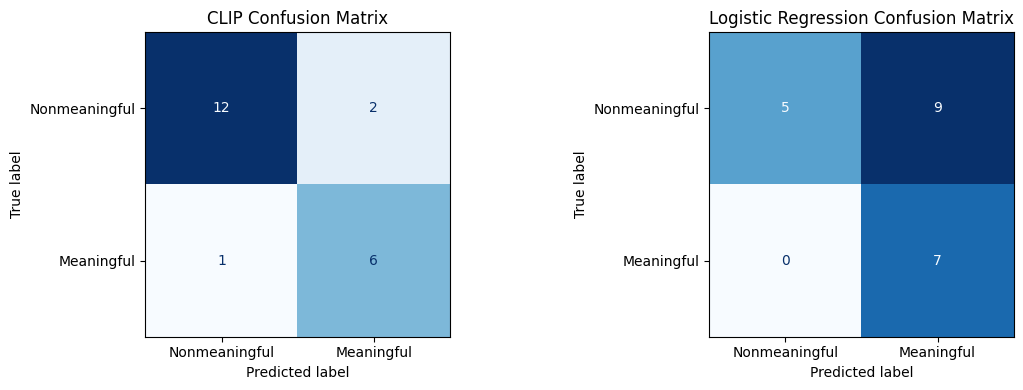

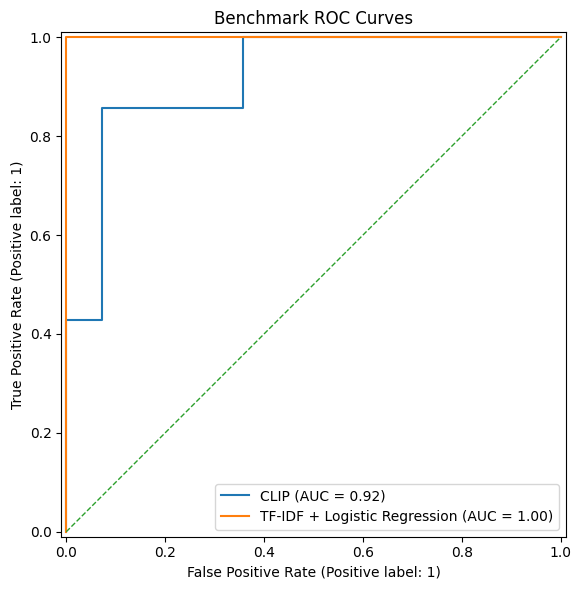

In [16]:

# ============================================================
# 1. PREPARE THE BENCHMARK EVALUATION DATA
# ============================================================

evaluation_base = benchmark_df.copy()

# Convert human-reviewed labels into numeric ground truth.
evaluation_base["ground_truth"] = pd.to_numeric(
    evaluation_base["alt_text_class"],
    errors="coerce"
)

# Keep records with valid binary ground-truth labels.
evaluation_base = evaluation_base[
    evaluation_base["ground_truth"].isin([0, 1])
].copy()

print("Records with valid ground-truth labels:",
      len(evaluation_base))


# ============================================================
# 2. PREPARE CLIP EVALUATION DATA
# ============================================================

clip_eval_df = evaluation_base.copy()

clip_eval_df["clip_prediction"] = pd.to_numeric(
    clip_eval_df["clip_prediction"],
    errors="coerce"
)

clip_eval_df["clip_similarity"] = pd.to_numeric(
    clip_eval_df["clip_similarity"],
    errors="coerce"
)

clip_eval_df = clip_eval_df.dropna(
    subset=["clip_prediction", "clip_similarity"]
).copy()

clip_eval_df = clip_eval_df[
    np.isfinite(clip_eval_df["clip_similarity"])
].copy()

clip_eval_df["ground_truth"] = (
    clip_eval_df["ground_truth"].astype(int)
)

clip_eval_df["clip_prediction"] = (
    clip_eval_df["clip_prediction"].astype(int)
)

print("\nCLIP evaluation records:", len(clip_eval_df))


# ============================================================
# 3. PREPARE LOGISTIC REGRESSION EVALUATION DATA
# ============================================================

lr_eval_df = evaluation_base.copy()

lr_eval_df["logistic_prediction"] = pd.to_numeric(
    lr_eval_df["logistic_prediction"],
    errors="coerce"
)

lr_eval_df["logistic_probability"] = pd.to_numeric(
    lr_eval_df["logistic_probability"],
    errors="coerce"
)

lr_eval_df = lr_eval_df.dropna(
    subset=[
        "logistic_prediction",
        "logistic_probability"
    ]
).copy()

lr_eval_df = lr_eval_df[
    np.isfinite(lr_eval_df["logistic_probability"])
].copy()

lr_eval_df["ground_truth"] = (
    lr_eval_df["ground_truth"].astype(int)
)

lr_eval_df["logistic_prediction"] = (
    lr_eval_df["logistic_prediction"].astype(int)
)

print("Logistic Regression evaluation records:",
      len(lr_eval_df))


# ============================================================
# 4. EVALUATION FUNCTION
# ============================================================

def evaluate_predictions(
    y_true,
    y_pred,
    y_score,
    model_name
):

    results = {
        "model": model_name,
        "n_samples": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "f1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

    if len(np.unique(y_true)) == 2:
        results["roc_auc"] = roc_auc_score(
            y_true, y_score
        )
    else:
        results["roc_auc"] = np.nan

    print(f"\n{'=' * 60}")
    print(model_name)
    print(f"{'=' * 60}")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=[
                "Nonmeaningful (0)",
                "Meaningful (1)"
            ],
            zero_division=0
        )
    )

    return results


# ============================================================
# 5. CALCULATE MODEL METRICS
# ============================================================

metrics = []

if len(clip_eval_df) > 0:

    y_true_clip = clip_eval_df[
        "ground_truth"
    ].to_numpy()

    clip_pred = clip_eval_df[
        "clip_prediction"
    ].to_numpy()

    clip_score = clip_eval_df[
        "clip_similarity"
    ].to_numpy()

    metrics.append(
        evaluate_predictions(
            y_true_clip,
            clip_pred,
            clip_score,
            "CLIP"
        )
    )

else:
    print("\nCLIP evaluation skipped: no valid predictions.")


if len(lr_eval_df) > 0:

    y_true_lr = lr_eval_df[
        "ground_truth"
    ].to_numpy()

    lr_pred = lr_eval_df[
        "logistic_prediction"
    ].to_numpy()

    lr_score = lr_eval_df[
        "logistic_probability"
    ].to_numpy()

    metrics.append(
        evaluate_predictions(
            y_true_lr,
            lr_pred,
            lr_score,
            "TF-IDF + Logistic Regression"
        )
    )

else:
    print(
        "\nLogistic Regression evaluation skipped: "
        "no valid predictions."
    )


# ============================================================
# 6. DISPLAY AND SAVE METRICS
# ============================================================

if len(metrics) > 0:

    metrics_df = pd.DataFrame(metrics)

    print("\nBENCHMARK PERFORMANCE SUMMARY")

    display(metrics_df.round(4))

    metrics_df.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "benchmark_metrics.csv"
        ),
        index=False
    )


    # ========================================================
    # 7. CONFUSION MATRICES
    # ========================================================

    available_models = []

    if len(clip_eval_df) > 0:
        available_models.append(
            ("CLIP", clip_eval_df,
             "clip_prediction")
        )

    if len(lr_eval_df) > 0:
        available_models.append(
            ("Logistic Regression", lr_eval_df,
             "logistic_prediction")
        )

    fig, axes = plt.subplots(
        1,
        len(available_models),
        figsize=(6 * len(available_models), 4)
    )

    if len(available_models) == 1:
        axes = [axes]

    for ax, (name, df, prediction_column) in zip(
        axes, available_models
    ):

        ConfusionMatrixDisplay.from_predictions(
            df["ground_truth"],
            df[prediction_column],
            labels=[0, 1],
            display_labels=[
                "Nonmeaningful",
                "Meaningful"
            ],
            cmap="Blues",
            ax=ax,
            colorbar=False
        )

        ax.set_title(f"{name} Confusion Matrix")

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "confusion_matrices.png"
        ),
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


    # ========================================================
    # 8. ROC CURVES
    # ========================================================

    roc_models = []

    if (
        len(clip_eval_df) > 0
        and len(clip_eval_df["ground_truth"].unique()) == 2
    ):
        roc_models.append(
            (
                clip_eval_df["ground_truth"],
                clip_eval_df["clip_similarity"],
                "CLIP"
            )
        )

    if (
        len(lr_eval_df) > 0
        and len(lr_eval_df["ground_truth"].unique()) == 2
    ):
        roc_models.append(
            (
                lr_eval_df["ground_truth"],
                lr_eval_df["logistic_probability"],
                "TF-IDF + Logistic Regression"
            )
        )

    if len(roc_models) > 0:

        fig, ax = plt.subplots(figsize=(7, 6))

        for y_true, y_score, name in roc_models:

            RocCurveDisplay.from_predictions(
                y_true,
                y_score,
                name=name,
                ax=ax
            )

        ax.plot(
            [0, 1],
            [0, 1],
            linestyle="--",
            linewidth=1
        )

        ax.set_title("Benchmark ROC Curves")

        plt.tight_layout()

        plt.savefig(
            os.path.join(
                OUTPUT_DIR,
                "roc_curves.png"
            ),
            dpi=200,
            bbox_inches="tight"
        )

        plt.show()

    else:
        print(
            "\nROC curves skipped: at least one model "
            "needs both ground-truth classes."
        )

else:
    print(
        "\nNo metrics could be calculated. "
        "Check the prediction-generation cells."
    )


## Interpretation notes

1. **No benchmark threshold tuning:** thresholds are loaded from the saved training configuration and applied unchanged.
2. **Different model inputs:** CLIP receives the image and its alt text; logistic regression receives only alt text, matching its training design.
3. **Ground truth matters:** do not treat `benchmark_original_label='failed'` with `label_granularity='document'` as an individual figure label unless the benchmark documentation explicitly defines it that way.
4. **Manual review:** rows marked `manual_review_required=True` are still predicted, but excluded from metrics by default.
5. **CLIP scoring must match training:** verify that the similarity formula here is identical to the formula used to select the saved CLIP threshold.
6. **Saved artifacts:** the notebook requires the fitted TF-IDF vectorizer and fitted logistic-regression model. It does not fit either on benchmark data.